# Figure 1c
Probability of a wild type at each monitored vertex given no fixation, at $r=1$.

In [1]:
import json

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mt

from fixloc import style as S

d = json.load(open('data.json'))
t, f, m = np.array(d['t']), np.array(d['f']), np.array(d['m'])
with np.errstate(divide='ignore', invalid='ignore'):
  wild = np.where(f[:, None] < 1, (1 - m) / (1 - f)[:, None], np.nan)
MONITORED = {1: 3, 4: 4, 8: 5, 11: 6}

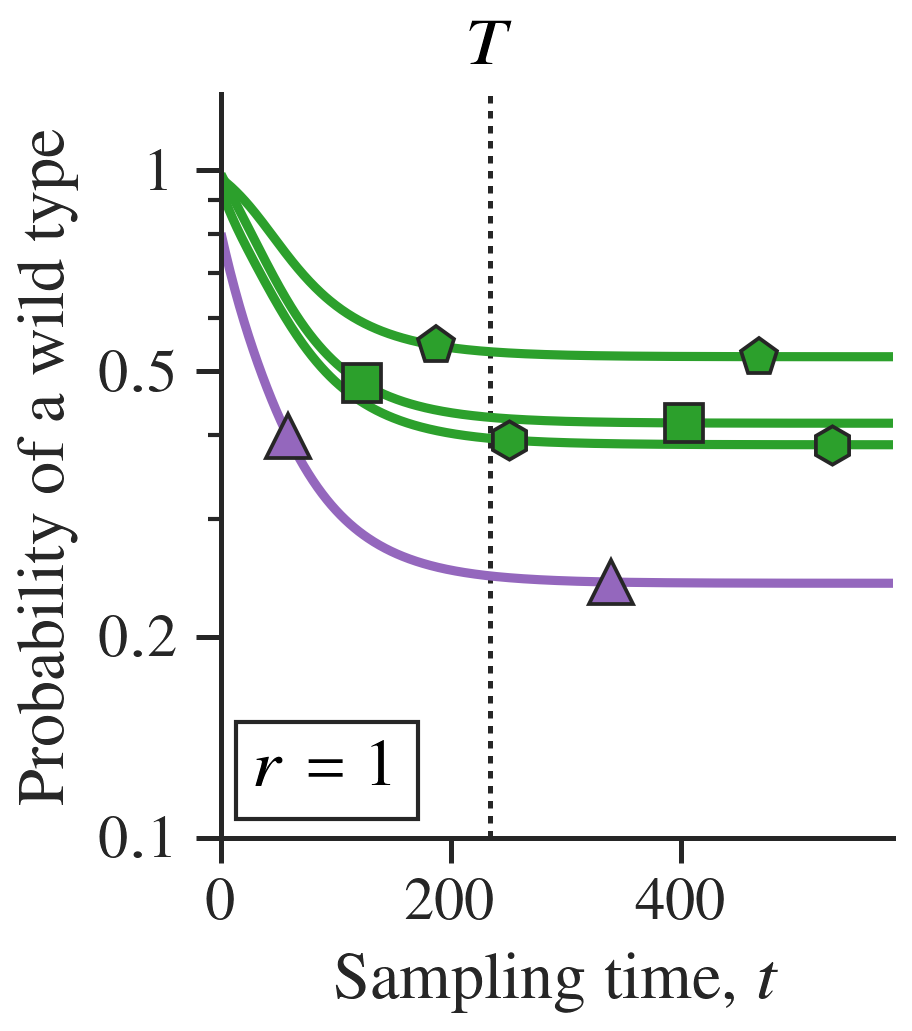

In [2]:
fig = plt.figure(figsize=(7.0, 3.1))
ax = fig.add_axes([0.6, 0.14, 0.16, 0.4])
T = d['T_expected']
tmax = 2.5 * T
for j, (v, n) in enumerate(MONITORED.items()):
  col = S.PURPLE if v < 3 else S.GREEN
  mk = [int(np.argmin(np.abs(t - tmax * q))) for q in (0.1 + 0.11 * j, 0.58 + 0.11 * j)]
  ax.plot(t, wild[:, v], color=col, lw=1.1, zorder=2)
  ms = 4.6 if n != 3 else 5.2
  ax.plot(t[mk], wild[mk, v], ls='', marker=S.POLY_MARKER[n], ms=ms, mfc=col, mec=S.INK, mew=0.45, zorder=3)
ax.axvline(T, color=S.INK, lw=0.6, ls=(0, (1.5, 1.5)), zorder=1)
ax.text(T, 1.02, r'$T$', fontsize=8, ha='center', va='bottom', transform=ax.get_xaxis_transform(), clip_on=False)
ylo, yt = (0.1, [0.1, 0.2, 0.5, 1])
ax.set_yscale('log')
ax.set_xlim(0, tmax)
ax.set_ylim(ylo, 1.3)
ax.set_yticks(yt)
ax.yaxis.set_major_formatter(mt.FuncFormatter(lambda v, _: r'$%g$' % v))
ax.yaxis.set_minor_locator(mt.LogLocator(base=10, subs=np.arange(2, 10) * 0.1))
ax.yaxis.set_minor_formatter(mt.NullFormatter())
ax.set_xlabel(r'Sampling time, $t$')
S.boxed(ax, 0.05, 0.05, r'$r=%g$' % d['r'], transform=ax.transAxes, ha='left', va='bottom')
ax.set_ylabel('Probability of a wild type')
S.save_panel(fig, 'c')